# 13 · Proyecto final: resolver un reto de Kaggle

[Kaggle](https://www.kaggle.com) organiza competiciones de aprendizaje automático. Este proyecto final resuelve
uno de sus retos clásicos de iniciación (*Getting Started*), **House Prices: Advanced Regression Techniques**:
predecir el precio de venta de viviendas en Ames (Iowa) a partir de 79 variables descriptivas. El flujo de
trabajo es el de cualquier proyecto serio: entender los datos y la métrica, fijar una referencia, construir
variables, validar bien, comparar modelos y solo entonces predecir.

**Aprenderás**
1. De dónde vienen los datos y si puedes usarlos (licencias)
2. La métrica de la competición y por qué se calcula sobre el logaritmo del precio
3. Una exploración que cambia decisiones: asimetría, valores atípicos, los predictores más fuertes
4. Referencias y después un `Pipeline` de scikit-learn con ingeniería de variables
5. Validación cruzada, comparación de modelos y mezcla
6. Qué impulsa las predicciones y cómo enviarías una solución a Kaggle

## 1. Los datos y si podemos usarlos
Los conjuntos de datos de Kaggle tienen sus propias licencias, y **los datos de las competiciones se rigen por las
reglas de cada competición**, que normalmente solo permiten usarlos en ella y prohíben redistribuirlos. Por eso un
curso no debería volver a publicar los archivos de una competición de Kaggle.

Los datos de esta competición son un subconjunto del **conjunto Ames Housing**, que Dean De Cock recopiló
precisamente para la docencia y publicó con el *Journal of Statistics Education* (2011). El conjunto completo
(2.930 ventas de 2006 a 2010) está disponible abiertamente, aquí a través de [OpenML](https://www.openml.org/d/43926)
(licencia: pública). Usamos ese, lo citamos y dejamos los archivos de la competición en Kaggle, donde puedes
descargarlos con tu propia cuenta para enviar una solución.

> De Cock, D. (2011). *Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester Regression
> Project.* Journal of Statistics Education, 19(3).

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

ames = fetch_openml(data_id=43926, as_frame=True, parser="auto").frame   # se descarga una vez y queda en caché
print(ames.shape)
ames[["Neighborhood", "Gr_Liv_Area", "Overall_Qual", "Year_Built", "Total_Bsmt_SF", "Garage_Cars", "Sale_Price"]].head()

(2930, 81)


,Neighborhood,Gr_Liv_Area,Overall_Qual,Year_Built,Total_Bsmt_SF,Garage_Cars,Sale_Price
0,North_Ames,1656,Above_Average,1960,1080,2,215000
1,North_Ames,896,Average,1961,882,1,105000
2,North_Ames,1329,Above_Average,1958,1329,1,172000
3,North_Ames,2110,Good,1968,2110,2,244000
4,Gilbert,1629,Average,1997,928,2,189900


## 2. La métrica
La competición puntúa la **raíz del error cuadrático medio entre los logaritmos** de los precios previstos y reales.
En escala logarítmica, un error del 10% cuesta lo mismo en una casa barata que en una cara, que es como piensa un
comprador en una mala estimación. Así que modelamos directamente `log(precio)`.

Reservamos el 25% de las ventas como una "clasificación" privada que solo se toca una vez, al final.

entrenamiento 2197, prueba reservada 733


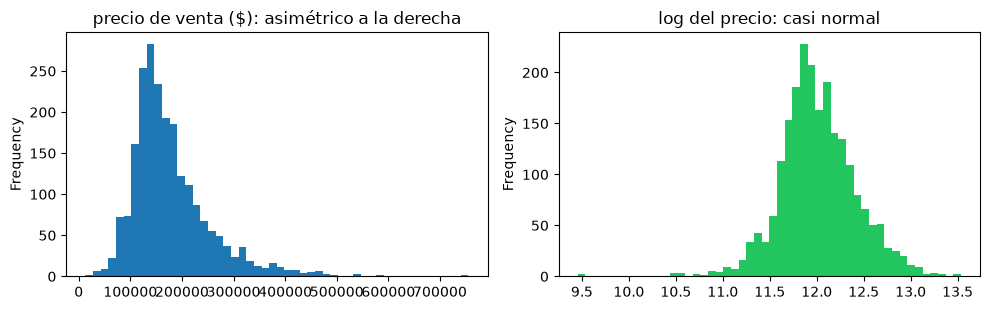

In [2]:
from sklearn.model_selection import train_test_split

def rmse_log(y_true_log, y_pred_log):
    return float(np.sqrt(np.mean((np.asarray(y_true_log) - np.asarray(y_pred_log)) ** 2)))

df = ames.copy()
df["log_price"] = np.log(df.pop("Sale_Price"))
train, test = train_test_split(df, test_size=0.25, random_state=42)
print(f"entrenamiento {len(train)}, prueba reservada {len(test)}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
np.exp(train["log_price"]).plot.hist(bins=50, ax=ax[0], title="precio de venta ($): asimétrico a la derecha")
train["log_price"].plot.hist(bins=50, ax=ax[1], title="log del precio: casi normal", color="#22c55e")
plt.tight_layout(); plt.show()

## 3. Una exploración que cambia decisiones

correlaciones numéricas más fuertes con el log del precio:
 Gr_Liv_Area       0.68
Garage_Cars       0.66
Garage_Area       0.63
Total_Bsmt_SF     0.61
Year_Built        0.60
First_Flr_SF      0.59
Full_Bath         0.57
Year_Remod_Add    0.57


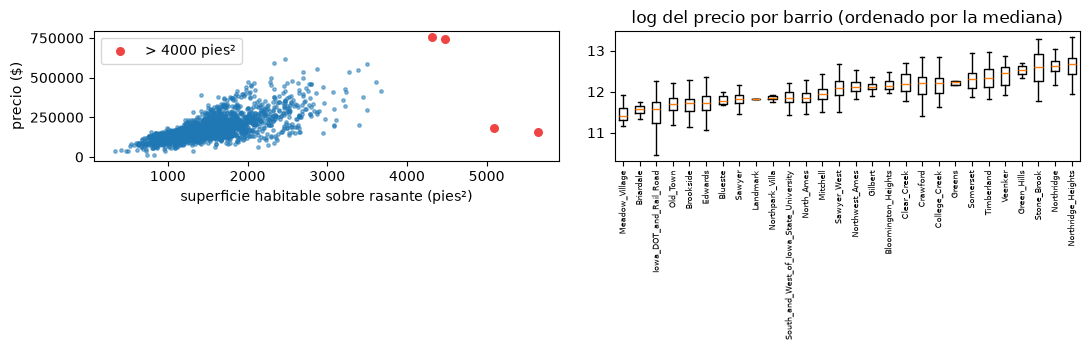

In [3]:
num = train.select_dtypes("number")
top = num.corr()["log_price"].drop("log_price").sort_values(key=abs, ascending=False).head(8)
print("correlaciones numéricas más fuertes con el log del precio:\n", top.round(2).to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].scatter(train["Gr_Liv_Area"], np.exp(train["log_price"]), s=6, alpha=.5)
big = train["Gr_Liv_Area"] > 4000
ax[0].scatter(train.loc[big, "Gr_Liv_Area"], np.exp(train.loc[big, "log_price"]), s=30, color="#ef4444", label="> 4000 pies²")
ax[0].set_xlabel("superficie habitable sobre rasante (pies²)"); ax[0].set_ylabel("precio ($)"); ax[0].legend()
order = train.groupby("Neighborhood", observed=True)["log_price"].median().sort_values().index
ax[1].boxplot([train.loc[train["Neighborhood"] == n, "log_price"] for n in order], showfliers=False)
ax[1].set_xticks(range(1, len(order) + 1)); ax[1].set_xticklabels(order, rotation=90, fontsize=6)
ax[1].set_title("log del precio por barrio (ordenado por la mediana)")
plt.tight_layout(); plt.show()

Dos hallazgos dan forma al modelo:
- **El tamaño y la calidad dominan**, y el barrio desplaza todo el nivel de precios.
- Unas pocas **casas muy grandes se vendieron a precios bajos** (en rojo, ventas parciales de inmuebles poco
  comunes). La propia documentación de De Cock recomienda quitar las casas de más de 4.000 pies cuadrados en los
  modelos docentes; las quitamos solo del *entrenamiento*, nunca del conjunto de prueba.

## 4. Referencias
Todo modelo debe superar algo sencillo. El precio mediano y una regresión de una variable sobre la superficie
habitable:

In [4]:
from sklearn.linear_model import LinearRegression

train = train[train["Gr_Liv_Area"] <= 4000]
y_train, y_test = train["log_price"], test["log_price"]

print(f"predecir la mediana          : RMSE(log) {rmse_log(y_test, np.full(len(test), y_train.median())):.4f}")
lr = LinearRegression().fit(np.log(train[["Gr_Liv_Area"]]), y_train)
print(f"regresión lineal sobre log(área): RMSE(log) {rmse_log(y_test, lr.predict(np.log(test[['Gr_Liv_Area']]))):.4f}")

predecir la mediana          : RMSE(log) 0.4244
regresión lineal sobre log(área): RMSE(log) 0.2797


## 5. Ingeniería de variables dentro de un Pipeline
La ingeniería de variables escrita como función dentro de un `Pipeline` de scikit-learn se aplica igual a los datos
de entrenamiento, a las particiones de validación y a las casas nuevas, lo que evita el error más común en las
competiciones: filtrar información de los datos con los que se evalúa.

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

QUALITY = ["Very_Poor", "Poor", "Fair", "Below_Average", "Average", "Above_Average", "Good",
           "Very_Good", "Excellent", "Very_Excellent"]
GRADE = {"No_Basement": 0, "No_Garage": 0, "No_Fireplace": 0, "No_Pool": 0, "Poor": 1, "Fair": 2,
         "Typical": 3, "Good": 4, "Excellent": 5}

def engineer(X: pd.DataFrame) -> pd.DataFrame:
    X = X.drop(columns=["log_price"], errors="ignore").copy()
    X["Overall_Qual_n"] = X["Overall_Qual"].astype(str).map({q: i for i, q in enumerate(QUALITY, 1)})
    for col in ["Exter_Qual", "Kitchen_Qual", "Bsmt_Qual", "Heating_QC", "Fireplace_Qu", "Garage_Qual"]:
        X[col + "_n"] = X[col].astype(str).map(GRADE).fillna(0)
    X["Total_SF"] = X["Total_Bsmt_SF"] + X["First_Flr_SF"] + X["Second_Flr_SF"]
    X["Total_Baths"] = X["Full_Bath"] + 0.5 * X["Half_Bath"] + X["Bsmt_Full_Bath"] + 0.5 * X["Bsmt_Half_Bath"]
    X["Age_At_Sale"] = X["Year_Sold"] - X["Year_Built"]
    X["Years_Since_Remodel"] = X["Year_Sold"] - X["Year_Remod_Add"]
    X["Qual_x_Area"] = X["Overall_Qual_n"] * X["Gr_Liv_Area"]
    for col in ["Gr_Liv_Area", "Total_SF", "Lot_Area"]:
        X["log_" + col] = np.log1p(X[col])
    return X

fe = FunctionTransformer(engineer)
X_tr_preview = engineer(train)
print(f"{X_tr_preview.shape[1]} columnas tras la ingeniería de variables; nuevas: "
      f"{[c for c in X_tr_preview.columns if c not in ames.columns]}")

95 columnas tras la ingeniería de variables; nuevas: ['Overall_Qual_n', 'Exter_Qual_n', 'Kitchen_Qual_n', 'Bsmt_Qual_n', 'Heating_QC_n', 'Fireplace_Qu_n', 'Garage_Qual_n', 'Total_SF', 'Total_Baths', 'Age_At_Sale', 'Years_Since_Remodel', 'Qual_x_Area', 'log_Gr_Liv_Area', 'log_Total_SF', 'log_Lot_Area']


In [6]:
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import HistGradientBoostingRegressor

numeric = make_column_selector(dtype_include="number")
categorical = make_column_selector(dtype_exclude="number")

ridge = make_pipeline(
    fe,
    ColumnTransformer([("num", StandardScaler(), numeric),
                       ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=10), categorical)]),
    RidgeCV(alphas=np.logspace(-1, 3, 30)),
)

from sklearn.preprocessing import OrdinalEncoder

# Trees take categories as integer codes. The encoder is fitted on the training data only, so a category
# always gets the same code in training, validation and test (codes taken from each DataFrame's own
# pandas categories would not be consistent), and an unseen category becomes "missing".
cat_cols = list(X_tr_preview.select_dtypes(exclude="number").columns)
gbm = make_pipeline(
    fe,
    ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan,
                                              encoded_missing_value=np.nan), cat_cols)],
                      remainder="passthrough", verbose_feature_names_out=False).set_output(transform="pandas"),
    HistGradientBoostingRegressor(learning_rate=0.05, max_iter=600, max_leaf_nodes=15, min_samples_leaf=10,
                                  l2_regularization=1.0, categorical_features=cat_cols, random_state=0),
)

## 6. Validación cruzada y comparación
La validación cruzada de cinco particiones sobre el conjunto de entrenamiento estima cómo puntuaría cada modelo con
casas no vistas, sin tocar el conjunto de prueba reservado.

In [7]:
from sklearn.model_selection import KFold, cross_val_predict

cv = KFold(5, shuffle=True, random_state=0)
oof = {}
for name, model in {"Ridge (lineal)": ridge, "Gradient boosting (árboles)": gbm}.items():
    oof[name] = cross_val_predict(model, train, y_train, cv=cv)
    print(f"{name:<20} CV RMSE(log) {rmse_log(y_train, oof[name]):.4f}")

weights = np.linspace(0, 1, 21)
blend_scores = [rmse_log(y_train, w * oof["Ridge (lineal)"] + (1 - w) * oof["Gradient boosting (árboles)"]) for w in weights]
w_best = float(weights[int(np.argmin(blend_scores))])
print(f"mejor mezcla: {w_best:.2f} x Ridge + {1 - w_best:.2f} x boosting -> RMSE(log) en validación cruzada {min(blend_scores):.4f}")

Ridge (lineal)       CV RMSE(log) 0.1171


Gradient boosting (árboles) CV RMSE(log) 0.1188
mejor mezcla: 0.55 x Ridge + 0.45 x boosting -> RMSE(log) en validación cruzada 0.1137


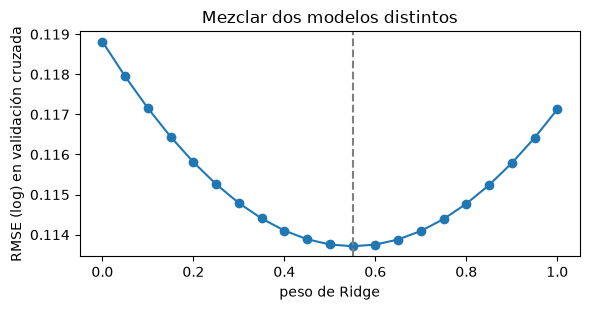

In [8]:
plt.figure(figsize=(6, 3.2))
plt.plot(weights, blend_scores, "o-"); plt.axvline(w_best, ls="--", color="grey")
plt.xlabel("peso de Ridge"); plt.ylabel("RMSE (log) en validación cruzada"); plt.title("Mezclar dos modelos distintos")
plt.tight_layout(); plt.show()

El modelo lineal y el conjunto de árboles cometen errores de distinto tipo, así que promediarlos supera a cada uno
por separado. Es el truco más fiable en las competiciones con datos tabulares.

## 7. La evaluación final, una sola vez
Se ajustan los dos modelos con todo el conjunto de entrenamiento y se puntúan las casas reservadas exactamente una vez.

In [9]:
ridge.fit(train, y_train); gbm.fit(train, y_train)
pred = {"Ridge (lineal)": ridge.predict(test), "Gradient boosting (árboles)": gbm.predict(test)}
pred["Mezcla"] = w_best * pred["Ridge (lineal)"] + (1 - w_best) * pred["Gradient boosting (árboles)"]
board = pd.Series({"referencia: mediana": rmse_log(y_test, np.full(len(test), y_train.median())),
                   "regresión sobre log(área)": rmse_log(y_test, lr.predict(np.log(test[["Gr_Liv_Area"]]))),
                   **{k: rmse_log(y_test, v) for k, v in pred.items()}}).sort_values()
print("RMSE(log) en la prueba reservada, menor es mejor:\n", board.round(4).to_string())
err = np.exp(pred["Mezcla"]) / np.exp(y_test) - 1
print(f"\nmezcla: error absoluto mediano del {np.median(np.abs(err)):.1%} del precio; "
      f"el 80% de las casas dentro de un {np.quantile(np.abs(err), .8):.1%}")

RMSE(log) en la prueba reservada, menor es mejor:
 Mezcla                         0.1101
Gradient boosting (árboles)    0.1108
Ridge (lineal)                 0.1167
regresión sobre log(área)      0.2797
referencia: mediana            0.4244

mezcla: error absoluto mediano del 5.2% del precio; el 80% de las casas dentro de un 9.8%


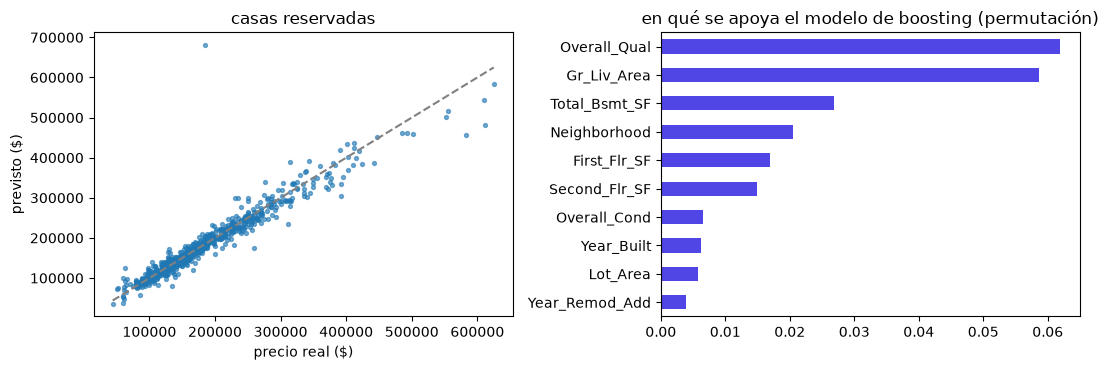

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].scatter(np.exp(y_test), np.exp(pred["Mezcla"]), s=8, alpha=.6)
lims = [np.exp(y_test).min(), np.exp(y_test).max()]
ax[0].plot(lims, lims, "--", color="grey"); ax[0].set_xlabel("precio real ($)"); ax[0].set_ylabel("previsto ($)")
ax[0].set_title("casas reservadas")

from sklearn.inspection import permutation_importance
X_test_only = test.drop(columns="log_price")
imp = permutation_importance(gbm, X_test_only, y_test, n_repeats=5, random_state=0, scoring="neg_root_mean_squared_error")
top = pd.Series(imp.importances_mean, index=X_test_only.columns).sort_values().tail(10)
top.plot.barh(ax=ax[1], color="#4f46e5"); ax[1].set_title("en qué se apoya el modelo de boosting (permutación)")
plt.tight_layout(); plt.show()

## 8. Enviar la solución a Kaggle
Un envío a Kaggle es un CSV con una fila por cada casa del archivo de prueba de la competición: `Id,SalePrice`. Así
lo producirías:

In [11]:
submission = pd.DataFrame({"Id": range(1, len(test) + 1), "SalePrice": np.exp(pred["Mezcla"]).round(0)})
print(submission.head().to_string(index=False))

 Id  SalePrice
  1   163755.0
  2   109983.0
  3   188201.0
  4   123558.0
  5   106777.0


Para competir de verdad:
1. Crea una cuenta en Kaggle, abre la competición *House Prices: Advanced Regression Techniques* y **acepta sus
   reglas**; después descarga `train.csv` y `test.csv` (o usa la herramienta de línea de órdenes `kaggle`).
2. Los archivos de la competición escriben las columnas de otra forma (`GrLivArea` en lugar de `Gr_Liv_Area`), usan
   algunos códigos de categoría distintos y marcan "sin sótano" y similares como valores ausentes. Renombra las
   columnas, rellena esos valores y reutiliza el mismo pipeline.
3. Ajusta con todos los datos de entrenamiento de Kaggle, predice `test.csv`, escribe `submission.csv` y súbelo.

Puntuaciones en torno a 0,12 de RMSE(log) son típicas de un buen modelo mezclado como este; la cabeza de la
clasificación está cerca de 0,10, a base de un trabajo cuidadoso con las variables y muchos modelos mezclados.

## Qué marcó la diferencia
| Paso | Por qué importó |
|---|---|
| leer la licencia | material del curso legal y reutilizable |
| modelar el logaritmo del precio | encaja con la métrica y doma la asimetría |
| quitar del entrenamiento los atípicos documentados | unas pocas casas enormes y baratas distorsionan un modelo lineal |
| variables dentro de un Pipeline | el mismo procesamiento en todas partes, sin filtraciones |
| validación cruzada antes del conjunto de prueba | una estimación honesta, y el conjunto de prueba sigue siendo un verdadero examen final |
| mezclar familias de modelos distintas | sus errores se compensan en parte |

## Ejercicios
1. Añade una codificación por objetivo de `Neighborhood` (el logaritmo medio del precio por barrio, calculado solo dentro de las particiones de validación cruzada) y mide el cambio.
2. Ajusta `learning_rate` y `max_leaf_nodes` del modelo de boosting con `RandomizedSearchCV`.
3. Usa `Longitude` y `Latitude` (incluidas en este conjunto) para añadir una variable de "distancia al centro de la ciudad".